<a href="https://colab.research.google.com/github/asadsalamasad7-source/CodeAlpha_ProjectName/blob/main/breast_cancer_data_visualization_and_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import missingno as msno  # Optional: for visualizing missing data

In [ ]:
# Load your dataset into a pandas DataFrame
# Make sure to upload 'breast-cancer.csv' to Colab or provide the correct file path / URL!
df = pd.read_csv('https://raw.githubusercontent.com/datasets/breast-cancer/master/data/breast-cancer.csv')


# Display the first few rows of the dataset
print(df.head())

     age mefalsepause tumor-size inv-falsedes falsede-caps  deg-malig breast  \
0  40-49   premefalse      15-19          0-2         True          3  right   
1  50-59         ge40      15-19          0-2        False          1  right   
2  50-59         ge40      35-39          0-2        False          2   left   
3  40-49   premefalse      35-39          0-2         True          3  right   
4  40-49   premefalse      30-34          3-5         True          2   left   

  breast-quad  irradiat                    class  
0     left_up     False        recurrence-events  
1     central     False  false-recurrence-events  
2    left_low     False        recurrence-events  
3    left_low      True  false-recurrence-events  
4    right_up     False        recurrence-events  


Missing values handled successfully!


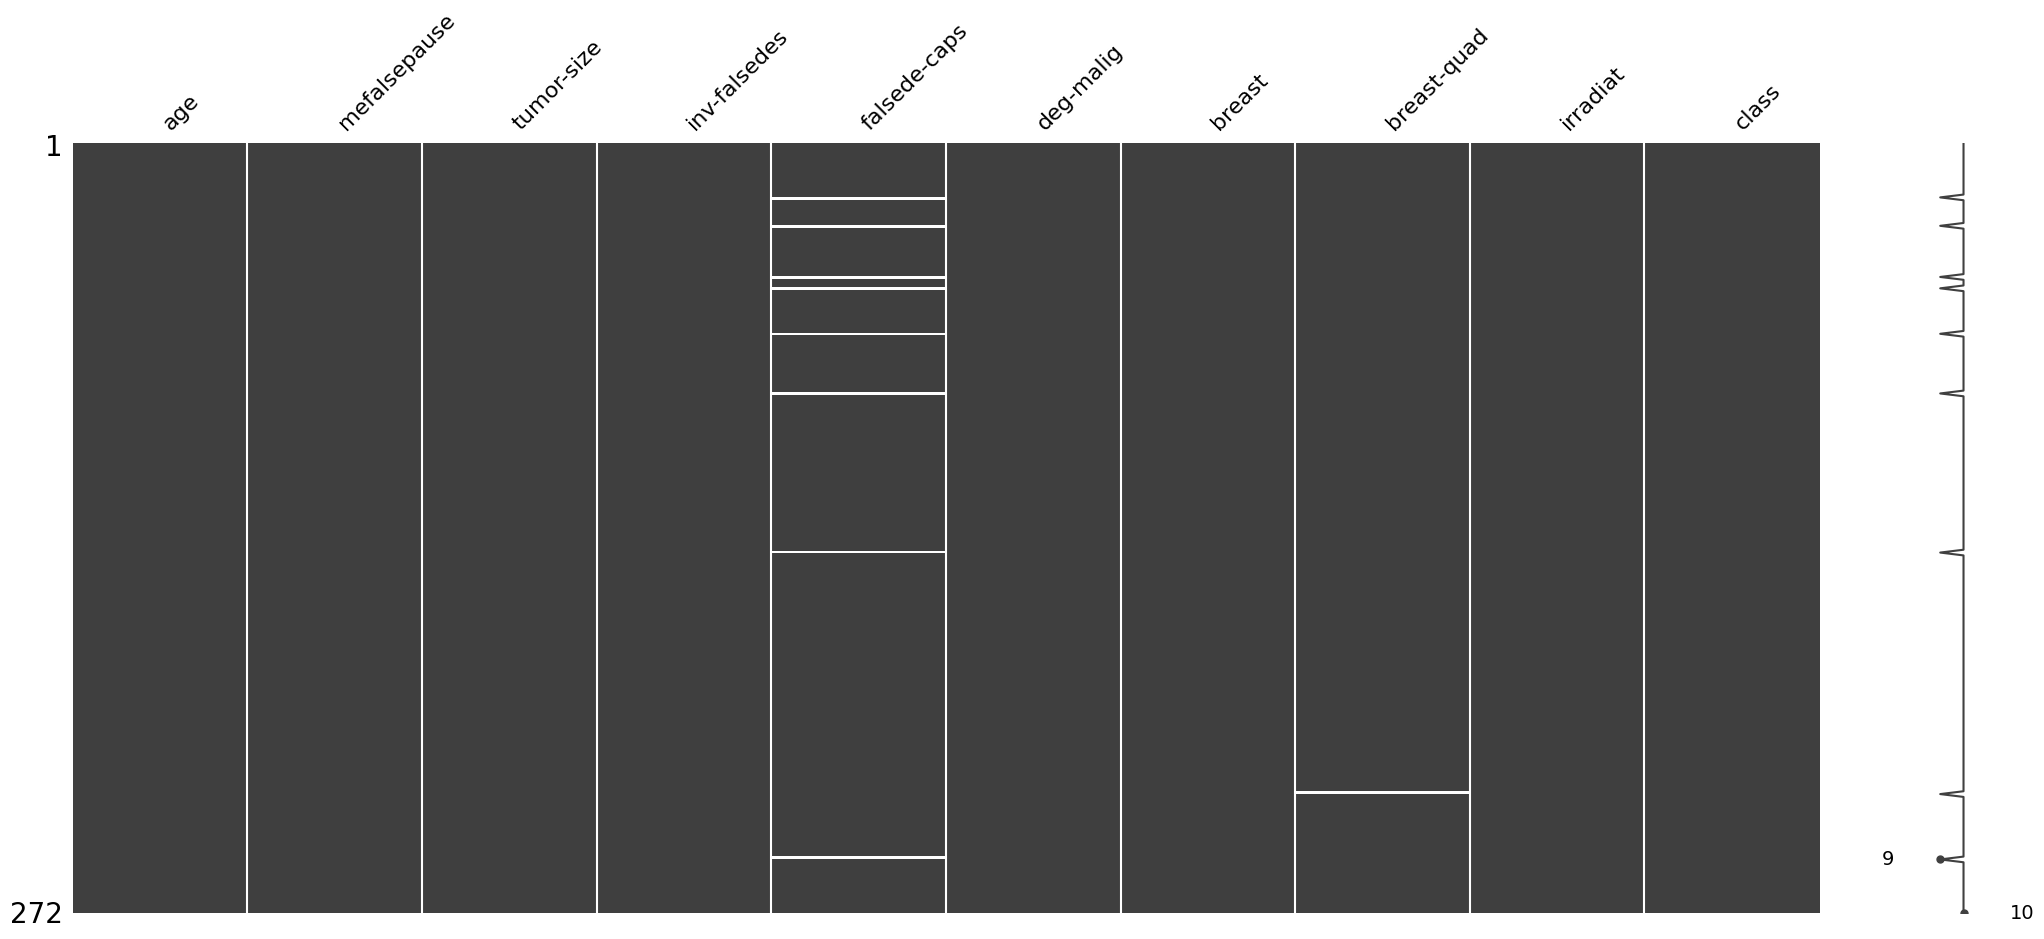

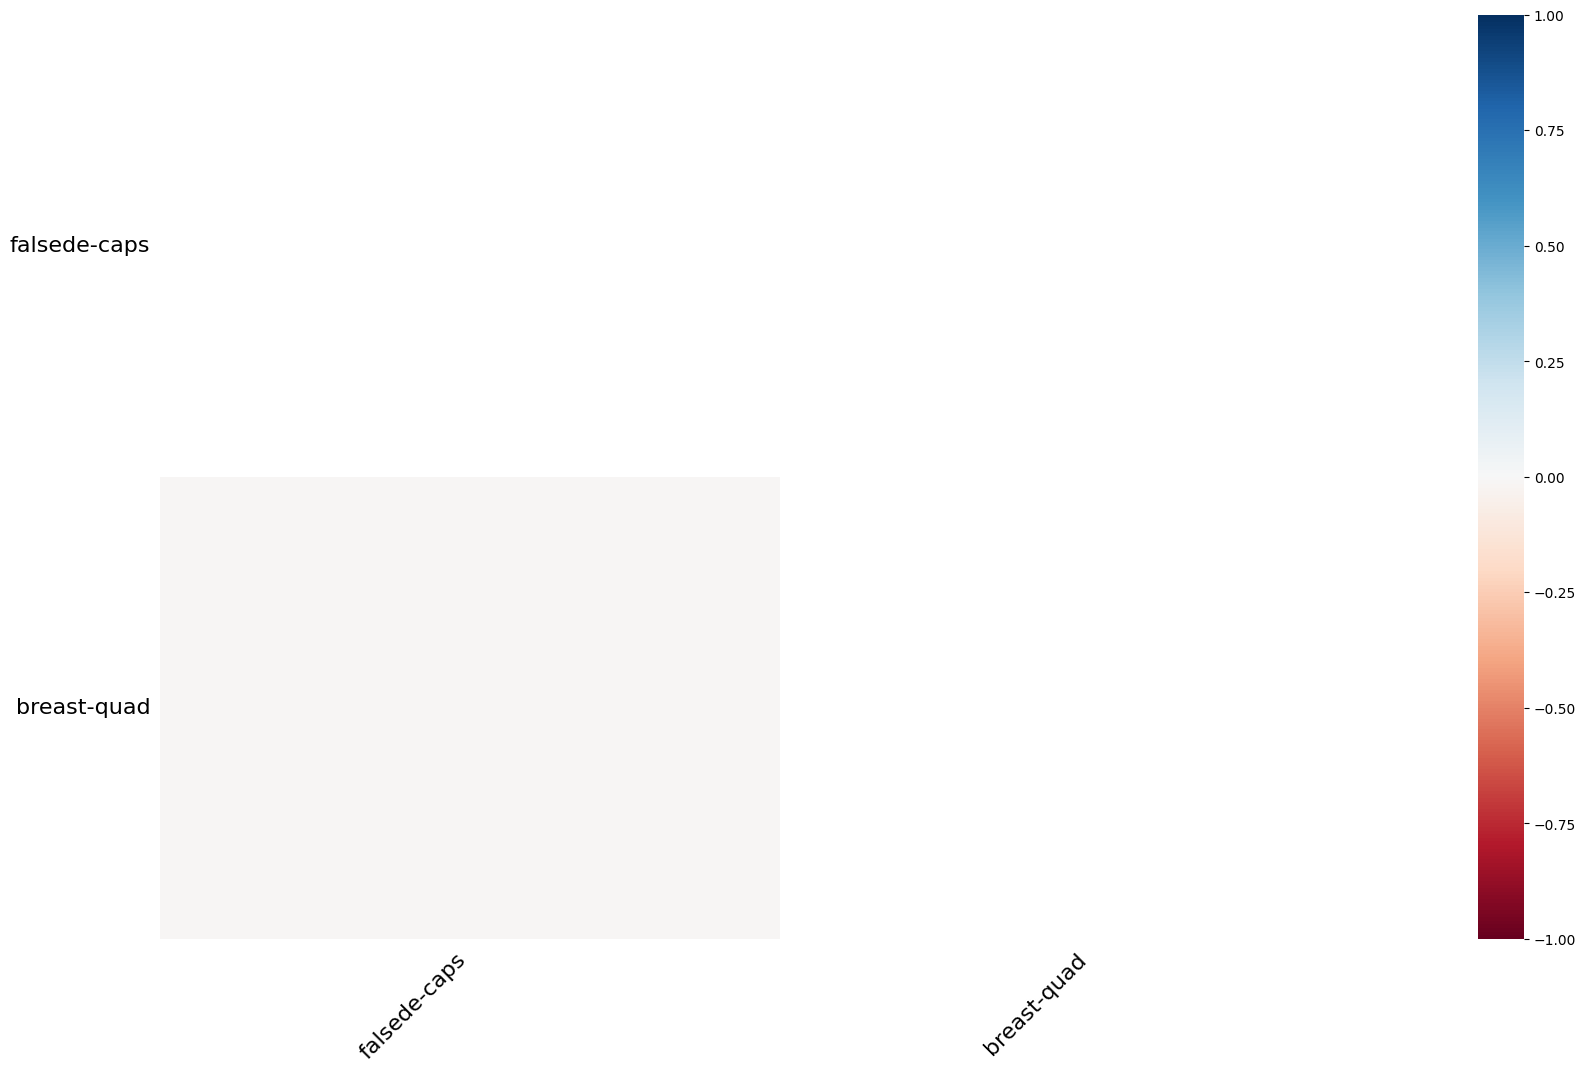

In [ ]:
# Opt-in to the future behavior to silence the pandas downcasting warning
pd.set_option('future.no_silent_downcasting', True)

# Visualize missing data (optional)
msno.matrix(df)
msno.heatmap(df)

# Drop rows with missing values
df_cleaned = df.dropna()

# Create a copy to fill missing values properly
df_filled = df.copy()

# Fill missing values based on data type
for col in df_filled.columns:
    if df_filled[col].dtype in ['int64', 'float64']:
        # Fill numeric columns with the mean
        df_filled[col] = df_filled[col].fillna(df_filled[col].mean())
    else:
        # Fill categorical/string columns with the mode (most frequent value)
        df_filled[col] = df_filled[col].fillna(df_filled[col].mode()[0])

print("Missing values handled successfully!")

In [ ]:
from scipy import stats

# Identify numeric columns for Z-score calculation
numeric_cols = df_cleaned.select_dtypes(include=[np.number]).columns

# Calculate Z-scores only on numeric columns
z_scores = np.abs(stats.zscore(df_cleaned[numeric_cols]))

# Filter out rows where any numeric column has a Z-score >= 3
df_no_outliers = df_cleaned[(z_scores < 3).all(axis=1)]
print(f"Rows before removing outliers: {len(df_cleaned)}")
print(f"Rows after removing outliers: {len(df_no_outliers)}")

# Or cap outliers at a threshold (using 'deg-malig' as our numeric column)
upper_limit = df_cleaned['deg-malig'].quantile(0.95)
df_capped = df_cleaned.copy()
df_capped['deg-malig'] = np.where(df_cleaned['deg-malig'] > upper_limit, upper_limit, df_cleaned['deg-malig'])
print("Outliers handled successfully!")

Rows before removing outliers: 263
Rows after removing outliers: 263
Outliers handled successfully!


In [ ]:
# Identify numeric columns
numeric_cols = df_cleaned.select_dtypes(include=[np.number]).columns

# Min-Max Scaling on numeric columns
scaler_minmax = MinMaxScaler()
df_scaled = df_cleaned.copy()
df_scaled[numeric_cols] = scaler_minmax.fit_transform(df_cleaned[numeric_cols])

# Z-score Standardization on numeric columns
scaler_std = StandardScaler()
df_standardized = df_cleaned.copy()
df_standardized[numeric_cols] = scaler_std.fit_transform(df_cleaned[numeric_cols])

print("Scaling and normalization completed successfully on numeric columns:", list(numeric_cols))

Scaling and normalization completed successfully on numeric columns: ['deg-malig']


In [ ]:
# Identify all categorical columns dynamically
categorical_cols = df_scaled.select_dtypes(exclude=[np.number]).columns.tolist()

# One-hot encoding for categorical variables
df_encoded = pd.get_dummies(df_scaled, columns=categorical_cols, drop_first=True)

# Display the encoded DataFrame
display(df_encoded.head())

,deg-malig,age_30-39,age_40-49,age_50-59,age_60-69,age_70-79,mefalsepause_lt40,mefalsepause_premefalse,tumor-size_10-14,tumor-size_15-19,...,inv-falsedes_6-8,inv-falsedes_9-11,falsede-caps_True,breast_right,breast-quad_left_low,breast-quad_left_up,breast-quad_right_low,breast-quad_right_up,irradiat_True,class_recurrence-events
0,1.0,False,True,False,False,False,False,True,False,True,...,False,False,True,True,False,True,False,False,False,True
1,0.0,False,False,True,False,False,False,False,False,True,...,False,False,False,True,False,False,False,False,False,False
2,0.5,False,False,True,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,True
3,1.0,False,True,False,False,False,False,True,False,False,...,False,False,True,True,True,False,False,False,True,False
4,0.5,False,True,False,False,False,False,True,False,False,...,False,False,True,False,False,False,False,True,False,True


In [ ]:
# Save the cleaned and preprocessed DataFrame to a new CSV file
df_encoded.to_csv('cleaned_preprocessed_data.csv', index=False)

print('Data cleaning and preprocessing complete. File saved as cleaned_preprocessed_data.csv')

Data cleaning and preprocessing complete. File saved as cleaned_preprocessed_data.csv


In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.preprocessing import StandardScaler

def load_data(filepath):
    return pd.read_csv(filepath)

def handle_missing_values(df):
    df_filled = df.copy()
    for col in df_filled.columns:
        if df_filled[col].dtype in ['int64', 'float64']:
            df_filled[col] = df_filled[col].fillna(df_filled[col].mean())
        else:
            df_filled[col] = df_filled[col].fillna(df_filled[col].mode()[0])
    return df_filled

def remove_outliers(df):
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    if len(numeric_cols) == 0:
        return df.copy()
    z_scores = np.abs(stats.zscore(df[numeric_cols]))
    # Keep rows where all numeric columns have z-score < 3
    return df[(z_scores < 3).all(axis=1)].copy()

def scale_data(df):
    df_scaled = df.copy()
    numeric_cols = df_scaled.select_dtypes(include=[np.number]).columns
    if len(numeric_cols) > 0:
        scaler = StandardScaler()
        df_scaled[numeric_cols] = scaler.fit_transform(df_scaled[numeric_cols])
    return df_scaled

def encode_categorical(df):
    categorical_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
    return pd.get_dummies(df, columns=categorical_cols, drop_first=True)

def save_data(df, output_filepath):
    df.to_csv(output_filepath, index=False)

# Example usage with our actual dataset:
df_raw = load_data('https://raw.githubusercontent.com/datasets/breast-cancer/master/data/breast-cancer.csv')
df_prep = handle_missing_values(df_raw)
df_prep = remove_outliers(df_prep)
df_prep = scale_data(df_prep)
df_prep = encode_categorical(df_prep)
save_data(df_prep, 'cleaned_preprocessed_data.csv')

print("Pipeline executed successfully!")
display(df_prep.head())

Pipeline executed successfully!


,deg-malig,age_30-39,age_40-49,age_50-59,age_60-69,age_70-79,mefalsepause_lt40,mefalsepause_premefalse,tumor-size_10-14,tumor-size_15-19,...,inv-falsedes_6-8,inv-falsedes_9-11,falsede-caps_True,breast_right,breast-quad_left_low,breast-quad_left_up,breast-quad_right_low,breast-quad_right_up,irradiat_True,class_recurrence-events
0,1.28,False,True,False,False,False,False,True,False,True,...,False,False,True,True,False,True,False,False,False,True
1,-1.44,False,False,True,False,False,False,False,False,True,...,False,False,False,True,False,False,False,False,False,False
2,-0.08,False,False,True,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,True
3,1.28,False,True,False,False,False,False,True,False,False,...,False,False,True,True,True,False,False,False,True,False
4,-0.08,False,True,False,False,False,False,True,False,False,...,False,False,True,False,False,False,False,True,False,True
